# DSA211 Topic 3: Model Complexity and the Bias–Variance Trade-Off (Monte Carlo Study)
By Group 4: Daniel, Nicholas, Adam, Aarav, Imran

### AI Declaration

During the span of the project we used Claude for writing and debugging Python code. While Claude was assisting with coding, we were documenting our project's workflow through our inferences of the project's requirement via the notebook-markdown feature.

### 0. Research Question

**Main question:** How do bias², variance and irreducible error contribute to expected test error as the degree $d$ of a polynomial regression (fitted by OLS) rises from 1 to 10?

| # | Theme | Sub-question | Where in this notebook |
|---|---|---|---|
| 1 | Decomposition | How do bias² and variance change with $d$, and does bias² + variance + σ² reproduce the expected test MSE? | Parts 2–3 |
| 2 | Optimal complexity | Which degree minimises expected test error, and does it match the true degree of 3? | Part 2 |
| 3 | Noise | How does the optimal degree change as σ rises from 0.2 to 1, and what does this imply for real data where σ is unknown? | Parts 4 and 6 |
| 4 | Regularisation | When polynomial regression is replaced by a LASSO path, with effective degrees of freedom as the complexity axis, how does the bias–variance profile compare with polynomial OLS? | Part 5 |

Because the data are simulated from a known function, bias and variance can be measured exactly against the truth, which is not possible with real data.

**DGP**

- $X \sim U(-1, 1)$
- $f(x) = x^3 - x$ (true degree 3)
- $\varepsilon \sim N(0, \sigma^2)$, independent of $X$; $Y = f(X) + \varepsilon$
- Baseline $\sigma = 0.3$; noise extension $\sigma \in \{0.2, 0.5, 1\}$
- Training size $n = 50$; $R = 500$ simulation runs; polynomial OLS of degree $d = 1, \dots, 10$ (excluding degree 0)
- LASSO extension: LASSO on the 10 standardised powers $x, x^2, \dots, x^{10}$ along a grid of 40 penalties λ




In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.exceptions import ConvergenceWarning
import warnings

pd.set_option('display.precision', 4)
pd.set_option('display.width', 140)

SEED     = 2026
N_TRAIN  = 50
R        = 500
T        = 200
DEGREES  = np.arange(1, 11)
D        = len(DEGREES)
BASE     = 0.3
SIGMAS   = [0.2, 0.3, 0.5, 1.0]
POWERS   = np.arange(1, 11)
LASSO_ALPHAS = np.logspace(np.log10(0.4), -3.5, 40)
def f(x):
    return x**3 - x

### 0.1 Signal-to-noise ratio (SNR)

Y in Y = f(x) + ε contains both signal and noise captured. **The signal to noise ratio** is used because noise level does not indicate whether noise is large or small, but rather relative to the signal of the true function. In other words, SNR tells us how much of the variation in Y comes from the signal rather than the noise.

SNR also shows where a more complex model pays off. Specifically, a less complex model may capture the signal less but captures less noise (variance); a more complex model may capture more signal but also more noise. SNR can show us the "sweet spot" of the bias-variance tradeoff. (see 0.2 Predictions before simulation)

Since $f$ is an odd function and $X \sim U(-1, 1)$ is symmetric about 0, $E[f(X)] = 0$, so

$$\operatorname{Var}(f(X)) = E[(x^3 - x)^2] = \tfrac{1}{7} - \tfrac{2}{5} + \tfrac{1}{3} = \tfrac{8}{105} \approx 0.076$$

At a noise level of $\sigma = 0.3$  
Signal to noise ratio $$= \operatorname{Var}(f(X)) / \sigma^2 = \tfrac{0.076}{0.3^2} \approx 0.85$$  



In [2]:
var_f = 8/105
x_chk = np.random.default_rng(1).uniform(-1, 1, 2_000_000)
print(f"Var f (analytic) = {var_f:.5f}   Var f (2M draws) = {f(x_chk).var():.5f}   SD f = {np.sqrt(var_f):.3f}")
snr = pd.DataFrame({'sigma': SIGMAS, 'sigma^2': np.square(SIGMAS)})
snr['SNR = Var(f)/sigma^2'] = var_f / snr['sigma^2']
snr

Var f (analytic) = 0.07619   Var f (2M draws) = 0.07620   SD f = 0.276


,sigma,sigma^2,SNR = Var(f)/sigma^2
0,0.2,0.04,1.9048
1,0.3,0.09,0.8466
2,0.5,0.25,0.3048
3,1.0,1.00,0.0762


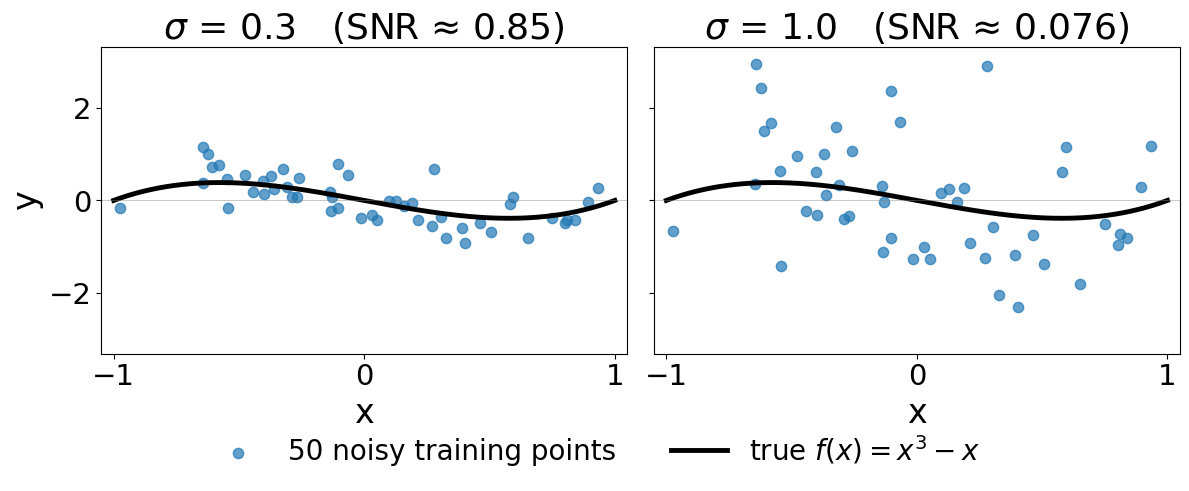

In [3]:
rng_fig = np.random.default_rng(SEED)
x_fig = rng_fig.uniform(-1, 1, N_TRAIN)            # 50 training inputs
z_fig = rng_fig.standard_normal(N_TRAIN)           # same noise draws for both panels
xs = np.linspace(-1, 1, 400)
FS_TITLE, FS_LABEL, FS_TICK, FS_LEGEND = 26, 24, 21, 20   # large fonts so the figure stays readable on a slide

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, s in zip(axes, [BASE, 1.0]):
    ax.scatter(x_fig, f(x_fig) + s * z_fig, s=55, alpha=0.7, label=f'{N_TRAIN} noisy training points')
    ax.plot(xs, f(xs), color='black', lw=3.5, label=r'true $f(x)=x^3-x$')
    snr_s = var_f / s**2
    ax.set_title(rf'$\sigma$ = {s}   (SNR ≈ {snr_s:.2f})' if snr_s >= 0.1 else rf'$\sigma$ = {s}   (SNR ≈ {snr_s:.3f})',
                 fontsize=FS_TITLE)
    ax.set_xlim(-1.05, 1.05); ax.set_ylim(-3.3, 3.3); ax.set_xticks([-1, 0, 1])
    ax.axhline(0, color='grey', lw=0.6, alpha=0.5); ax.set_xlabel('x', fontsize=FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
axes[0].set_ylabel('y', fontsize=FS_LABEL)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False, fontsize=FS_LEGEND)   # below both panels
plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.savefig('slide4_dgp_signal_noise.png', dpi=200)
plt.show()

### 0.2 Predictions before simulation

1.  **Bias² (H1).** Bias² is about 0.023 (= 4/175) for degrees 1 and 2, because the best straight-line or quadratic fit cannot capture the cubic ($f$ is odd, so adding $x^2$ does not help), and about 0 for degrees $d \ge 3$. Bias² **does not depend on σ**.



2.  **Variance (H2).** Variance generally rises with $d$. For $d \ge 3$, where OLS is unbiased for $f$, it scales exactly with σ² (Var/σ² is the same at every noise level); for $d < 3$ the random design adds a small σ-free component. Because variance rises as we add parameters, we judge a model by the reduction in bias² **and** the rise in variance together, not by variance alone. Near $x = \pm 1$ variance is larger because of leverage (H5); this is a leverage effect, not exponential growth.


3.  **Irreducible error (H3).** The irreducible error is the same $\sigma^2$ at every degree as Var(ε) is always $\sigma^2$; however, it changes when we change our noise level $\sigma$. Hence, we predict that irreducible error doesn't change unless the noise level changes.

4. **Signal to noise ratio**: SNR = Var(f)/σ² falls as σ increases, by definition. At σ = 1 the signal is nearly invisible, so a simpler model may win.

5. **Extensions, varying noise level (H4)**: we believe that in a low noise-level environment, a more complex model such as model with polynomial degree 3 or more would outperform a model with polynomial 1. However, in a noisier environment, a complex model would "chase" observations in the training set and may result in higher test MSE. Of the extension's $\sigma$ = 0.2; $\sigma$ = 0.5; $\sigma$ = 1, we predict that model with polynomial degree 3 results in least test error when $\sigma$ = 0.2; 0.3, 0.5 and less complex model such as model with degree 1 would perform better at  $\sigma$ = 1.

6. **Extensions, LASSO (H6, H7)**: We predict that as lambda decreases, the penalty imposed on coefficients also decrease. As a result, the complexity of models increase, and according to the bias-variance tradeoff, $Bias^{2}$ decreases while variance increases. Moreover, at low noise, the addition of LASSO comes at a cost as degree-3 polynomial OLS already has a low variance. in other words, the bias introduced by LASSO's shrinkage would outweigh the variance reduction; hence, creating a "cost of shrinkage".

7. **Extensions, LASSO and noise (H8)**: as σ grows, the best λ grows (lower df) and the LASSO's position relative to polynomial OLS improves, because shrinkage buys a large variance cut for a little bias. At σ = 1 the LASSO may beat the best polynomial.

8. **Extensions, df estimate (H9)**: the number of nonzero coefficients + 1 agrees with the covariance definition of degrees of freedom, df = Σᵢ Cov(ŷᵢ, yᵢ)/σ².


## Part 1: Monte Carlo engine

In [4]:
def poly_pipe(d):
    # Course pipeline (Lab 7): standardise x, take its powers, fit OLS
    return Pipeline([('scale', StandardScaler()),
                     ('poly',  PolynomialFeatures(degree=int(d), include_bias=False)),
                     ('ols',   LinearRegression())])

def run_mc(n=N_TRAIN, R=R, T=T, seed=SEED, sigmas=SIGMAS):
    # Draw everything once, from independent streams.
    s_x0, s_x, s_z, s_star = np.random.SeedSequence(seed).spawn(4)
    x0 = np.sort(np.random.default_rng(s_x0).uniform(-1, 1, T))      # fixed test inputs (drawn ONCE)
    X  = np.random.default_rng(s_x).uniform(-1, 1, (R, n))           # training inputs, one row per run
    Z  = np.random.default_rng(s_z).standard_normal((R, n))          # training noise (standardised)
    Zs = np.random.default_rng(s_star).standard_normal((R, T))       # FRESH test noise for every run
    pred = {s: np.empty((R, D, T)) for s in sigmas}                  # predictions at x0, per sigma
    lev  = np.empty((R, D, T))                                       # leverage of each test input
    for r in range(R):
        for j, d in enumerate(DEGREES):
            for s in sigmas:
                y = f(X[r]) + s * Z[r]                               # same draws at every sigma
                model = poly_pipe(d).fit(X[r][:, None], y)
                pred[s][r, j] = model.predict(x0[:, None])
            # leverage v(x0)' (X'X)^-1 v(x0) depends only on the training inputs, not on y or sigma
            feats = model[:-1]                                       # fitted scaler + powers
            Dtr = np.column_stack([np.ones(n), feats.transform(X[r][:, None])])
            D0  = np.column_stack([np.ones(T), feats.transform(x0[:, None])])
            G = np.linalg.inv(Dtr.T @ Dtr)
            lev[r, j] = np.einsum('ti,ij,tj->t', D0, G, D0)
    return dict(x0=x0, X=X, Z=Z, Zs=Zs, pred=pred, lev=lev, n=n, R=R)

mc = run_mc()
x0 = mc['x0']
print('prediction array per sigma (runs, degrees, test points):', mc['pred'][BASE].shape)

# Sanity check (conditioning remedy): the pipeline fit equals numpy's ordinary polynomial fit
# for every degree, on 20 runs, using noisy training data at the baseline sigma.
gap = np.zeros(D)
for r in range(20):
    y_r = f(mc['X'][r]) + BASE * mc['Z'][r]
    for j, d in enumerate(DEGREES):
        monomial_pred = np.polyval(np.polyfit(mc['X'][r], y_r, d), x0)
        gap[j] = max(gap[j], np.abs(mc['pred'][BASE][r, j] - monomial_pred).max())
print('Largest |pipeline fit - np.polyfit fit| over 20 runs and 200 test inputs, by degree:')
print(pd.Series(gap, index=DEGREES).map('{:.1e}'.format).to_string())

prediction array per sigma (runs, degrees, test points): (500, 10, 200)
Largest |pipeline fit - np.polyfit fit| over 20 runs and 200 test inputs, by degree:
1     5.6e-16
2     7.8e-16
3     3.4e-15
4     3.7e-15
5     5.2e-15
6     1.8e-14
7     4.0e-14
8     1.0e-13
9     1.2e-13
10    6.0e-13


## Part 2: Finding bias, variance and test MSE

Each degree-model predicts 500 times, each time on a new training set, generating 500 OLS-model for each degree-model. Then each OLS-model is tested on the same 200 test-observations.

Let $\hat y_r(x_0)$ be predicted y values of each model in run $r$:

**Variance and bias² estimators.**

- $\widehat{\text{Var}}(x_0) = \frac{1}{R-1}\sum_r (\hat y_r - \bar y)^2$
- $\widehat{\text{Bias}}^2(x_0)$: with $\bar y = \frac1R\sum_r \hat y_r(x_0)$ and independent runs, $\operatorname{Var}(\bar y) = V/R$,

$$
\begin{aligned}
&E\big[(\bar y - f(x_0))^2\big] = \text{Bias}^2(x_0) + V/R \\
&\widehat{\text{Bias}}{}^2(x_0) = (\bar y - f(x_0))^2 - \widehat{\mathrm{Var}}(x_0)/R \\
&E\big[\widehat{\text{Bias}}{}^2(x_0)\big] = \text{Bias}^2(x_0) + V/R - V/R = \text{Bias}^2(x_0)
\end{aligned}
$$

- Expected test MSE: $\widehat{\text{MSE}}(x_0) = \frac{1}{R}\sum_r \big(y^*_r(x_0) - \hat y_r(x_0)\big)^2$ with $y^*_r(x_0) = f(x_0) + \varepsilon^*_r$ and **fresh $\varepsilon^*_r$ in every run**.

$Bias^2$, Variance, and MSE is then averaged over the 200 test-observations.

In [5]:
def decompose_pred(yhat, x0_, Zs, sigma, index, index_name, n_boot=200, seed=SEED):
    # yhat: predictions (runs, models, test points). Works for any family of models.
    R_, M = yhat.shape[0], yhat.shape[1]
    f0   = f(x0_)
    var  = yhat.var(axis=0, ddof=1)                         # (D, T)
    bias2 = (yhat.mean(axis=0) - f0)**2 - var / R_          # bias-corrected
    ystar = f0 + sigma * Zs                                 # fresh noise at fixed x0, every run
    sq    = (ystar[:, None, :] - yhat)**2                   # (R, D, T)
    mse_pt  = sq.mean(axis=0)                               # (D, T)
    mse_run = sq.mean(axis=2)                               # (R, D): test MSE of each run
    # exact algebraic identity (no noise involved)
    exact_gap = np.abs(bias2.mean(1) + var.mean(1) - ((yhat - f0)**2).mean(axis=(0, 2))).max()
    out = pd.DataFrame({
        index_name: index,
        'bias2': bias2.mean(1),
        'variance': var.mean(1),
        'irreducible': sigma**2,
    })
    out['bias2+var+sigma2'] = out['bias2'] + out['variance'] + out['irreducible']
    out['test_MSE'] = mse_pt.mean(1)
    out['gap'] = out['test_MSE'] - out['bias2+var+sigma2']
    out['MSE_se'] = mse_run.std(axis=0, ddof=1) / np.sqrt(R_)
    # Monte Carlo standard errors of bias2 and variance: bootstrap over the R runs
    if n_boot:
        rng_b = np.random.default_rng(seed)
        bb, vb = np.empty((n_boot, M)), np.empty((n_boot, M))
        for b in range(n_boot):
            yb = yhat[rng_b.integers(0, R_, R_)]
            v = yb.var(axis=0, ddof=1)
            bb[b] = ((yb.mean(axis=0) - f0)**2 - v / R_).mean(1)
            vb[b] = v.mean(1)
        out.insert(2, 'bias2_se', bb.std(axis=0, ddof=1))
        out.insert(4, 'variance_se', vb.std(axis=0, ddof=1))
    return out.set_index(index_name), dict(bias2=bias2, var=var, mse_pt=mse_pt, mse_run=mse_run, exact_gap=exact_gap)

def decompose(mc, sigma, n_boot=200, seed=SEED):
    return decompose_pred(mc['pred'][sigma], mc['x0'], mc['Zs'], sigma, DEGREES, 'degree', n_boot, seed)

res, raw = {}, {}
for s in SIGMAS:
    res[s], raw[s] = decompose(mc, s)

print(f"Exact identity check (bias2 + var = mean (yhat - f)^2), largest gap over degrees: {raw[BASE]['exact_gap']:.2e}\n")
res[BASE]

Exact identity check (bias2 + var = mean (yhat - f)^2), largest gap over degrees: 8.88e-16



,bias2,bias2_se,variance,variance_se,irreducible,bias2+var+sigma2,test_MSE,gap,MSE_se
degree,,,,,,,,,
1,2.2234e-02,1.0901e-04,0.0050,0.0002,0.09,0.1173,0.1180,0.0008,0.0006
2,2.2377e-02,1.7372e-04,0.0089,0.0003,0.09,0.1213,0.1222,0.0009,0.0007
3,-1.3488e-05,1.6012e-05,0.0085,0.0003,0.09,0.0984,0.0992,0.0008,0.0006
4,-1.3512e-05,2.4007e-05,0.0118,0.0005,0.09,0.1018,0.1025,0.0007,0.0007
5,-1.9307e-05,3.7803e-05,0.0184,0.0029,0.09,0.1084,0.1088,0.0004,0.0030
6,-1.2375e-06,5.7705e-05,0.0223,0.0025,0.09,0.1123,0.1130,0.0006,0.0026
7,2.1291e-05,1.3780e-04,0.0397,0.0054,0.09,0.1298,0.1301,0.0004,0.0055
8,-1.4952e-04,8.4433e-04,0.2175,0.1398,0.09,0.3073,0.3072,-0.0002,0.1355
9,-8.0014e-04,9.7310e-04,0.4630,0.2328,0.09,0.5522,0.5528,0.0006,0.2547


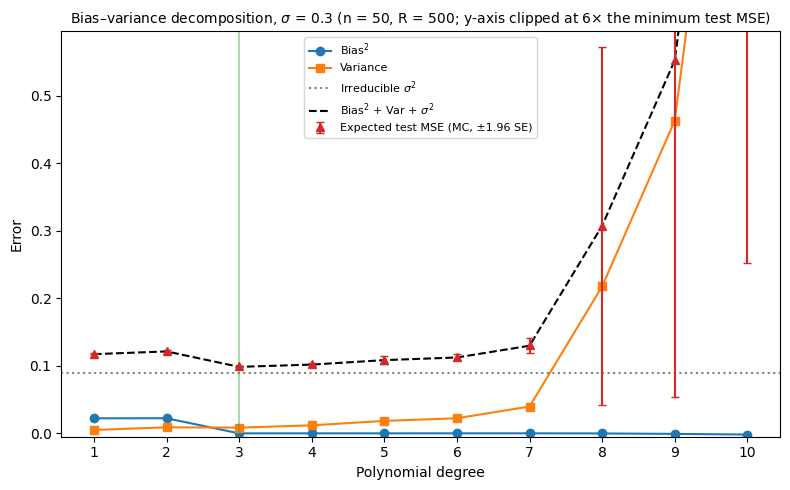

In [6]:
# Bias-variance decomposition at the baseline noise level only (sigma = 0.3); all four noise levels are compared in Part 4
t = res[BASE]
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t.index, t['bias2'], 'o-', label=r'Bias$^2$')
ax.plot(t.index, t['variance'], 's-', label='Variance')
ax.axhline(BASE**2, color='grey', ls=':', label=r'Irreducible $\sigma^2$')
ax.plot(t.index, t['bias2+var+sigma2'], 'k--', label=r'Bias$^2$ + Var + $\sigma^2$')
ax.errorbar(t.index, t['test_MSE'], yerr=1.96 * t['MSE_se'], fmt='^', color='tab:red', capsize=3, label='Expected test MSE (MC, ±1.96 SE)')
ax.axvline(t['test_MSE'].idxmin(), color='tab:green', alpha=.4)
ax.set_xticks(DEGREES); ax.set_ylim(-0.005, 6 * t['test_MSE'].min())   # high-degree variance is huge; axis clipped for readability
ax.set_xlabel('Polynomial degree'); ax.set_ylabel('Error')
ax.set_title(rf'Bias–variance decomposition, $\sigma$ = {BASE} (n = {N_TRAIN}, R = {R}; y-axis clipped at 6× the minimum test MSE)', fontsize=10)
ax.legend(fontsize=8); plt.tight_layout(); plt.show()


### 2.1 Optimal complexity vs the true degree at σ = 0.3

In [7]:
t = res[BASE]
best_mse = t['test_MSE'].idxmin()
best_dec = (t['bias2'] + t['variance']).idxmin()
print(f"Degree minimising Monte-Carlo test MSE            : {best_mse}")
print(f"Degree minimising bias^2 + variance (less noisy)   : {best_dec}")
print("True degree of f                                  : 3")
t.loc[[best_mse - 1, best_mse, best_mse + 1] if 1 < best_mse < 10 else [best_mse], ['bias2', 'variance', 'test_MSE', 'MSE_se']]

Degree minimising Monte-Carlo test MSE            : 3
Degree minimising bias^2 + variance (less noisy)   : 3
True degree of f                                  : 3


,bias2,variance,test_MSE,MSE_se
degree,,,,
2,2.2377e-02,0.0089,0.1222,0.0007
3,-1.3488e-05,0.0085,0.0992,0.0006
4,-1.3512e-05,0.0118,0.1025,0.0007


### 2.2 Are neighbouring degrees really different?

Looking at the transitions between polynomial degrees, Bias^2, Variance, and Test MSE do vary; however, the magnitude of variation is different between transitions.

*   **Transition in degree $1 \to 2$:**  **Bias²** doesn't drop because a strictly even function $x^2$ doesn't help model the strictly odd function $x^3 - x$ as it's incapable of matching the odd function's curvature.  Variance increases from 0.0050 to 0.0089 as the extra parameter adds complexity, so Test MSE rises slightly (0.1180 to 0.1222) instead of improving.

*   **Transition in degree $2 \to 3$:** We observe a **massive drop in Bias²** ($\approx -0.0224$) which completely dominates any change in variance (variance does not rise here; it dips slightly from 0.0089 to 0.0085). As a result, there is a statistically significant decrease in Test MSE.

*   **Transition in degree $3 \to 4$:** Bias² has already hit zero, so estimating with 1 extra parameter does not reduce it further. However, estimating the extra parameter increases Variance ($\approx +0.0033$), leading to a net increase in Test MSE. This shows us that degree 4 is, indeed, worse than degree 3 purely due to its higher complexity which introduces unnecessary variance.


*   **Transition in degree $4 \to 10$:** Bias² remains at zero, but Variance keeps climbing (0.012 at degree 4 to 1.29 at degree 10), much faster than the number of parameters. Again, degrees above 3 perform worse than degree 3. This is the variance side of the **bias-variance tradeoff**; Part 3 shows the rise is a leverage effect concentrated near $x = \pm 1$, not exponential growth.

In [8]:
rows = []
for s in SIGMAS:
    mr = raw[s]['mse_run']                       # (R, D): test MSE of each run and degree
    best = int(res[s]['test_MSE'].idxmin())
    for d in DEGREES:
        if d == best or abs(d - best) > 2:
            continue
        diff = mr[:, d - 1] - mr[:, best - 1]
        se = diff.std(ddof=1) / np.sqrt(len(diff))
        rows.append(dict(sigma=s, best_degree=best, compared_degree=int(d),
                         MSE_difference=diff.mean(), paired_se=se, z=diff.mean() / se))
pd.DataFrame(rows).set_index(['sigma', 'compared_degree'])

best_degree  MSE_difference  paired_se        z
sigma compared_degree                                                 
0.2   1                          3          0.0214     0.0003  80.6496
      2                          3          0.0243     0.0004  67.1254
      4                          3          0.0014     0.0002   8.6113
      5                          3          0.0043     0.0013   3.3091
0.3   1                          3          0.0188     0.0005  41.4427
      2                          3          0.0230     0.0005  45.3856
      4                          3          0.0032     0.0004   8.6113
      5                          3          0.0096     0.0029   3.3091
0.5   1                          3          0.0107     0.0010  10.5717
      2                          3          0.0190     0.0009  20.2153
      4                          3          0.0090     0.0010   8.6113
      5                          3          0.0266     0.0081   3.3091
1.0   2                          1          0.0276     0.0020  13.5727
      3                          1          0.0272     0.0035   7.8115

- Bias² → For degrees 1-2, bias² is flat at 0.022, while from degrees 3 onward, the bias² is about 0. The negative values represent the Monte Carlo noise from bias correction. This is consistent with our prediction of about 0.023 for bias², and about 0 for d >= 3, which does not depend on σ. Bias² at d = 1 and d = 2 is the same within Monte Carlo error, since f is odd, so adding x² does not improve the fit.

- Variance → It rises with d, at 0.005 at d = 1, 0.012 at d = 4, 1.29 at d = 10, except for a slight dip from d = 2 to d = 3 (0.0089 to 0.0085, within about one standard error here, but clear at σ = 0.2, where Var/σ² falls from 0.138 to 0.094). The shape of degree 2 cannot match the true shape of degree 3 (Parabolic vs S-shaped), so its fit shifts with both the noise and where the random training data lands, while degree 3 only shifts with noise.

- Irreducible error→ Is the same at every degree, since it is just a calculation of σ² from noise level.

- Test-MSE minimum→ Is at d = 3, which is the true degree. Degrees 3, 4 and 5 are close in size (0.0992, 0.1025, 0.1088), and the single-degree standard errors are about 0.0006 (d = 3, 4) and 0.003 (d = 5). The paired differences give a clearer picture: d = 4 is worse than d = 3 by 0.0032 (z ≈ 8.6) and d = 5 by 0.0096 (z ≈ 3.3). So degree 3 is reliably the best, but the cost of overshooting by one degree is small, about 3%. The cost of undershooting is large (d = 1 and 2 are about 19–23% worse).

- Bias² + variance + σ² reproduce the test MSE, to within Monte Carlo error. The gap (test MSE minus the sum) is between about −0.0002 and +0.0012 across all degrees, and the small gaps come from the random test noise, which is shared across degrees.

## Part 3: Variance and leverage

The dashed lines show $\sigma^2 \times$ the average leverage over the 500 designs (valid for $d \ge 3$, where OLS is unbiased for $f$); solid lines are the empirical variances.

For OLS, prediction variance is directly proportional to leverage:
$\operatorname{Var}(\hat y(x_0)\mid X) = \sigma^2\, v(x_0)^\top (X^\top X)^{-1} v(x_0)$

Because leverage is "how unusual an observation is in its predictor space" and higher order polynomial deform the predictor space, we can expect that models with degree 5 or above inflate variance by exaggerating the effect of high-leverage observations.

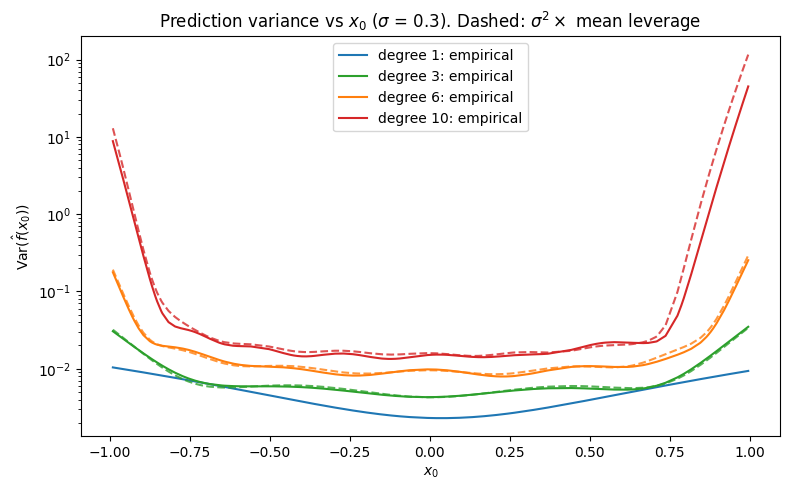

Mean empirical variance / (sigma^2 * mean leverage), degrees 1-10:
[1.307 1.409 1.004 1.014 1.057 0.961 0.94  1.01  0.904 0.83 ]

Variance at |x0| > 0.9 divided by variance at |x0| < 0.1:
Degree
1       3.93
2       4.61
3       5.73
4       6.36
5      12.00
6      11.45
7      24.27
8     153.16
9     309.12
10    810.08


In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
for d, c in zip([1, 3, 6, 10], ['tab:blue', 'tab:green', 'tab:orange', 'tab:red']):
    j = d - 1
    ax.plot(x0, raw[BASE]['var'][j], color=c, label=f'degree {d}: empirical')
    if d >= 3:
        ax.plot(x0, BASE**2 * mc['lev'][:, j].mean(axis=0), color=c, ls='--', alpha=.8)
ax.set_yscale('log'); ax.set_xlabel(r'$x_0$'); ax.set_ylabel(r'Var$(\hat f(x_0))$')
ax.set_title(r'Prediction variance vs $x_0$ ($\sigma$ = 0.3). Dashed: $\sigma^2\times$ mean leverage')
ax.legend(); plt.tight_layout(); plt.show()

# How close is theory to simulation? (theory is exact for d >= 3 only)
ratio = (raw[BASE]['var'] / (BASE**2 * mc['lev'].mean(axis=0))).mean(axis=1)
print(f'Mean empirical variance / (sigma^2 * mean leverage), degrees 1-10:\n{np.round(ratio, 3)}')
edge = np.abs(x0) > 0.9
print('\nVariance at |x0| > 0.9 divided by variance at |x0| < 0.1:\nDegree')
print(pd.Series(raw[BASE]['var'][:, edge].mean(1) / raw[BASE]['var'][:, np.abs(x0) < 0.1].mean(1), index=DEGREES).round(2).to_string())

We checked how closely the Monte Carlo variance matches the OLS prediction variance, σ² × average leverage. A ratio of 1 means they agree. (The formula is exact only for $d \ge 3$, where OLS is unbiased for $f$.)

Here, we see that the ratio floats around 1 with some degree-model having a lower empirical variance than theoretical, while some having higher:
- Model with degree (1, 2, 3, 4, 5, 8) has higher empirical variance.
  
  Respectively, (1.307;  1.409; 1.004; 1.014; 1.057; 1.01)

- On the other hand, model with degree (6, 7, 9, 10) has lower empirical variance.

  Respectively, (0.961; 0.94; 0.904; 0.83)

The largest deviation from a perfect ratio of 1 comes from model with degree 1, 2, and 10 because of model misspecification and explosion of variance, respectively.

- Degrees 1 and 2: These models are misspecified (they cannot represent the cubic), so their fitted curve also changes from sample to sample with the random design $X$. That adds variance that σ² × leverage does not include, which is why the ratios are above 1 (1.307 and 1.409). This is the σ-free design component predicted in H2.

- Degree 10: Although it is theoretically unbiased, a degree-10 fit with 50 points is very unstable near the boundaries of our domain (-1, 1), where a point has training data on one side only. This is why its ratio (0.83) is the noisiest: the variance is heavy-tailed, so the average over 500 runs is imprecise.

The rise toward the edges is a leverage effect, not exponential growth. For degree 10, the prediction variance at the boundary ($|x_0| > 0.9$) is about 810 times larger than at the centre ($|x_0| < 0.1$).

## Part 4: Noise-level extension

Predictions H1, H2 and H4 are tested below using the **same** simulated designs at every σ.

In [10]:
# H2: variance / sigma^2 should be the same at every sigma for d >= 3
vr = pd.DataFrame({f'sigma={s}': res[s]['variance'] / s**2 for s in SIGMAS})
vr['max/min'] = vr.max(axis=1) / vr.min(axis=1)
print('Variance / sigma^2 by degree (constant across sigma for d >= 3; d < 3 includes a sigma-free component):')
display(vr.round(4))

# H1: bias^2 should not depend on sigma
b2 = pd.DataFrame({f'sigma={s}': res[s]['bias2'] for s in SIGMAS})
b2['max-min'] = b2.max(axis=1) - b2.min(axis=1)
print('Bias^2 by degree and sigma (should not change with sigma):')
display(b2.round(4))

# Empirical variance vs sigma^2 x average leverage, at every sigma (d >= 3)
lev_bar = mc['lev'].mean(axis=0)             # (D, T)
lv = pd.DataFrame({f'sigma={s}': (raw[s]['var'] / (s**2 * lev_bar)).mean(axis=1) for s in SIGMAS},
                  index=DEGREES).loc[3:]
print('Empirical variance / (sigma^2 x mean leverage), averaged over x0, degrees 3-10 (1 = matches theory):')
display(lv.round(3))

Variance / sigma^2 by degree (constant across sigma for d >= 3; d < 3 includes a sigma-free component):


,sigma=0.2,sigma=0.3,sigma=0.5,sigma=1.0,max/min
degree,,,,,
1,0.0724,0.0558,0.0479,0.0450,1.6082
2,0.1377,0.0992,0.0798,0.0717,1.9194
3,0.0940,0.0940,0.0940,0.0940,1.0000
4,0.1313,0.1313,0.1313,0.1313,1.0000
5,0.2049,0.2049,0.2049,0.2049,1.0000
6,0.2482,0.2482,0.2482,0.2482,1.0000
7,0.4415,0.4415,0.4415,0.4415,1.0000
8,2.4163,2.4163,2.4163,2.4163,1.0000
9,5.1443,5.1443,5.1443,5.1443,1.0000


Bias^2 by degree and sigma (should not change with sigma):


,sigma=0.2,sigma=0.3,sigma=0.5,sigma=1.0,max-min
degree,,,,,
1,0.0222,0.0222,0.0222,0.0221,0.0001
2,0.0224,0.0224,0.0223,0.0221,0.0003
3,-0.0000,-0.0000,-0.0000,-0.0001,0.0001
4,-0.0000,-0.0000,-0.0000,-0.0002,0.0001
5,-0.0000,-0.0000,-0.0001,-0.0002,0.0002
6,-0.0000,-0.0000,-0.0000,-0.0000,0.0000
7,0.0000,0.0000,0.0001,0.0002,0.0002
8,-0.0001,-0.0001,-0.0004,-0.0017,0.0016
9,-0.0004,-0.0008,-0.0022,-0.0089,0.0085


Empirical variance / (sigma^2 x mean leverage), averaged over x0, degrees 3-10 (1 = matches theory):


,sigma=0.2,sigma=0.3,sigma=0.5,sigma=1.0
3,1.004,1.004,1.004,1.004
4,1.014,1.014,1.014,1.014
5,1.057,1.057,1.057,1.057
6,0.961,0.961,0.961,0.961
7,0.940,0.940,0.940,0.940
8,1.010,1.010,1.010,1.010
9,0.904,0.904,0.904,0.904
10,0.830,0.830,0.830,0.830


Reading the two tables. For $d \ge 3$ the variance/σ² columns are identical because OLS is unbiased for $f$ there, so $\hat y - f = \sigma\, \hat{b}$, where $\hat b$ is the fit to the standardised noise; because the same draws are reused at every σ, the variance scales exactly with σ². For $d < 3$ the misspecified fit varies with the random design $X$, giving a σ-free component. The bias² estimates at degrees ≥ 8 move with σ only because their Monte Carlo noise is of order Var/R, which scales with σ²; the true bias² does not depend on σ.

In [11]:
# H4: optimal degree by sigma, against the large-n approximation
def theory_total(d, s, n=N_TRAIN):
    return (4/175 if d < 3 else 0.0) + (d + 1) * s**2 / n

rows = []
for s in SIGMAS:
    t = res[s]
    rows.append(dict(sigma=s,
                     SNR=var_f / s**2,
                     optimal_degree_MC_test_MSE=t['test_MSE'].idxmin(),
                     optimal_degree_bias2_plus_var=(t['bias2'] + t['variance']).idxmin(),
                     predicted_degree=min(DEGREES, key=lambda d: theory_total(d, s)),
                     test_MSE_at_1=t.loc[1, 'test_MSE'], test_MSE_at_3=t.loc[3, 'test_MSE']))
opt = pd.DataFrame(rows).set_index('sigma')
opt

,SNR,optimal_degree_MC_test_MSE,optimal_degree_bias2_plus_var,predicted_degree,test_MSE_at_1,test_MSE_at_3
sigma,,,,,,
0.2,1.9048,3,3,3,0.0655,0.0441
0.3,0.8466,3,3,3,0.1180,0.0992
0.5,0.3048,3,3,3,0.2862,0.2756
1.0,0.0762,1,1,1,1.0751,1.1023


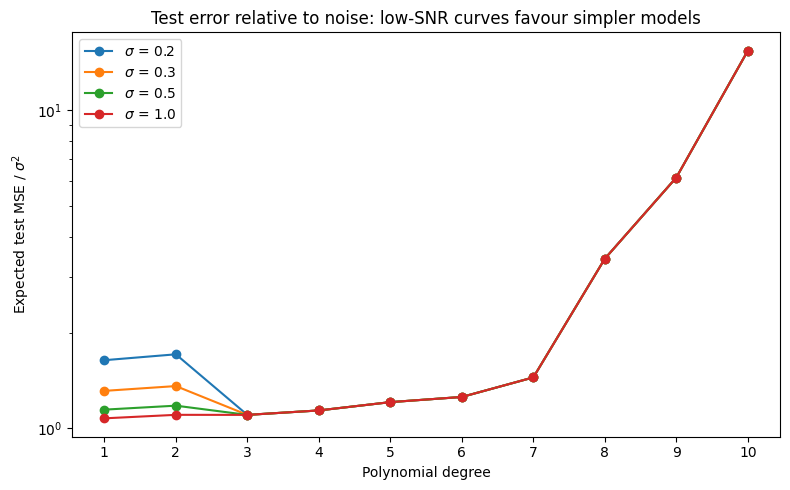

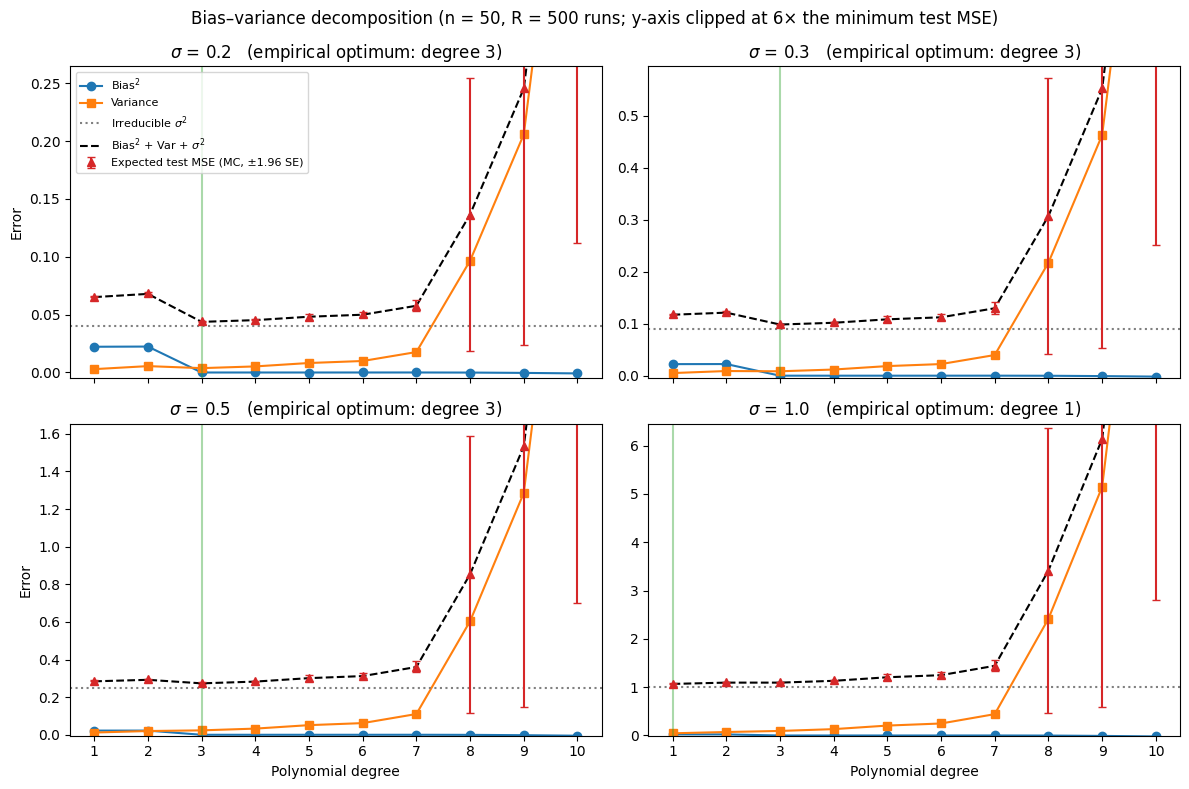

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
for s in SIGMAS:
    t = res[s]
    ax.plot(t.index, t['test_MSE'] / s**2, 'o-', label=rf'$\sigma$ = {s}')
ax.set_yscale('log'); ax.set_xticks(DEGREES)
ax.set_xlabel('Polynomial degree'); ax.set_ylabel(r'Expected test MSE / $\sigma^2$')
ax.set_title('Test error relative to noise: low-SNR curves favour simpler models')
ax.legend(); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, s in zip(axes.ravel(), SIGMAS):
    t = res[s]
    ax.plot(t.index, t['bias2'], 'o-', label=r'Bias$^2$')
    ax.plot(t.index, t['variance'], 's-', label='Variance')
    ax.axhline(s**2, color='grey', ls=':', label=r'Irreducible $\sigma^2$')
    ax.plot(t.index, t['bias2+var+sigma2'], 'k--', label=r'Bias$^2$ + Var + $\sigma^2$')
    ax.errorbar(t.index, t['test_MSE'], yerr=1.96*t['MSE_se'], fmt='^', color='tab:red', capsize=3, label='Expected test MSE (MC, ±1.96 SE)')
    best = t['test_MSE'].idxmin()
    ax.axvline(best, color='tab:green', alpha=.4)
    ax.set_title(rf'$\sigma$ = {s}   (empirical optimum: degree {best})')
    ax.set_xticks(DEGREES); ax.set_ylim(-0.005, 6 * t['test_MSE'].min())   # high-degree variance is huge; axis clipped for readability
for ax in axes[1]: ax.set_xlabel('Polynomial degree')
for ax in axes[:, 0]: ax.set_ylabel('Error')
axes[0, 0].legend(fontsize=8)
plt.suptitle(f'Bias–variance decomposition (n = {N_TRAIN}, R = {R} runs; y-axis clipped at 6× the minimum test MSE)')
plt.tight_layout(); plt.show()

In Part 2, we looked at the bias-variance trade-off at a fixed noise level. Here, we look at how it changes as noise increases. Across the four noise levels, squared bias remains almost unchanged, as expected. For degrees 1 and 2, the estimates stay around 0.022, while from degree 3 onwards squared bias is theoretically zero, since these models can represent the true cubic function. Because the noise has mean zero, changing σ does not affect the expected fitted predictions, but it does affect their variability. Some bias-corrected estimates are negative, particularly at higher degrees and σ = 1, but this reflects Monte Carlo estimation uncertainty rather than genuinely negative squared bias.

While changing the noise has little effect on bias, its effect on variance is much clearer. Variance increases with noise and, from degree 3 onwards, with model complexity. For degrees 3 to 10, the variance/σ² ratio remains constant across noise levels, as predicted, but rises sharply from approximately 0.094 at degree 3 to 14.38 at degree 10. This exact constancy also comes from using the same training inputs and standardised noise draws at each σ. The increase with degree is consistent with the leverage behaviour observed earlier, where high-degree polynomials become particularly unstable near the boundaries. Degrees 1 and 2 do not follow the same pattern, since their misspecification introduces additional variation from the randomly sampled training inputs.

These differences also affect which polynomial degree performs best. As predicted (H4), degree 3 achieves the lowest test MSE at σ = 0.2, 0.3 and 0.5. Its advantage over degree 1 does become smaller, though, with the MSE difference falling from 0.0214 at σ = 0.2 to 0.0107 at σ = 0.5. Among the four noise levels tested, degree 1 only becomes optimal at σ = 1, with a test MSE of 1.0751 compared with 1.1023 for degree 3. The difference of 0.0272 is considerably larger than its paired standard error of 0.0035.

Although degree 3 correctly represents our underlying function, estimating its additional coefficients from noisy data also introduces more variance. At σ = 1, degree 1 has a variance of approximately 0.045 compared with 0.094 for degree 3. This reduction of around 0.049 more than compensates for its squared bias of about 0.022, allowing a simpler but misspecified model to predict better. Since irreducible noise affects both models equally, it is this bias-variance balance that determines which performs best. This shows why knowing the true functional form does not necessarily guarantee the lowest prediction error with limited data. In practice, where the true function and noise level are usually unknown, we would compare model complexities through cross-validation rather than automatically favouring the theoretically correct model.


## Part 5: LASSO path extension

The brief's extension replaces polynomial regression with a **LASSO path** and uses **effective degrees of freedom** as the complexity axis, then compares the bias–variance profiles.

**Set-up (Week 9 practice).** In every run the LASSO receives all 10 powers $x, \dots, x^{10}$ of the training inputs, **standardised** with `StandardScaler` fitted on that run's training data (the penalty is not scale-invariant). As in Lab 9, `Lasso` is fitted separately at each of 40 values of λ, with an unpenalised intercept. The penalty uses sklearn's scaling, $\frac{1}{2n}\text{RSS} + \alpha\sum_j|\beta_j|$.

**Same Monte Carlo design as Parts 1–4.** The LASSO is fitted on the **same** 500 training sets, predicts at the **same** 200 test inputs, and is scored against the **same** fresh test noise, at every σ. Comparisons with polynomial OLS are therefore paired run by run.

**Complexity axis.** $\widehat{\mathrm{df}}(\lambda)$ = average over runs of (number of nonzero coefficients + 1 for the intercept). For polynomial OLS, df = $d + 1$. Section 5.2 checks this estimate against the covariance definition (H9).

In [13]:
def run_lasso(mc, sigma, alphas=LASSO_ALPHAS):
    X, Z, x0_ = mc['X'], mc['Z'], mc['x0']
    R_, A, T_ = X.shape[0], len(alphas), len(x0_)
    pred    = np.empty((R_, A, T_))
    support = np.zeros((R_, A, len(POWERS)), dtype=bool)
    warned  = np.zeros(A, dtype=int)                       # non-converged fits, per penalty
    for r in range(R_):
        F  = X[r][:, None] ** POWERS
        scaler = StandardScaler().fit(F)                   # learned from this run's training data only
        Fs, F0 = scaler.transform(F), scaler.transform(x0_[:, None] ** POWERS)
        y  = f(X[r]) + sigma * Z[r]                        # same training data as the polynomial fits
        for k, a in enumerate(alphas):                     # Lab 9: one Lasso fit per penalty
            with warnings.catch_warnings(record=True) as w:
                warnings.simplefilter('always', ConvergenceWarning)
                m = Lasso(alpha=a, max_iter=300000, tol=1e-6).fit(Fs, y)
            warned[k] += len(w) > 0
            pred[r, k]    = m.predict(F0)
            support[r, k] = np.abs(m.coef_) > 1e-10
    return pred, support, warned

lasso_res, lasso_raw, lasso_support, lasso_warned = {}, {}, {}, {}
for s in SIGMAS:
    pred, sup, warned = run_lasso(mc, s)
    lasso_warned[s] = warned
    n_warn = warned.sum()
    tab, rw = decompose_pred(pred, x0, mc['Zs'], s, LASSO_ALPHAS, 'alpha')
    tab.insert(0, 'df', sup.sum(axis=2).mean(axis=0) + 1)
    lasso_res[s], lasso_raw[s], lasso_support[s] = tab, rw, sup
    print(f"sigma = {s}: {n_warn} of {R * len(LASSO_ALPHAS)} fits hit the iteration limit "
          f"({100 * n_warn / (R * len(LASSO_ALPHAS)):.2f}%); exact identity gap {rw['exact_gap']:.1e}")
    del pred

print(f"\nLASSO decomposition at the baseline sigma = {BASE} (every 3rd penalty shown):")
lasso_res[BASE].iloc[::3]

sigma = 0.2: 1 of 20000 fits hit the iteration limit (0.01%); exact identity gap 4.2e-17
sigma = 0.3: 14 of 20000 fits hit the iteration limit (0.07%); exact identity gap 1.1e-16
sigma = 0.5: 59 of 20000 fits hit the iteration limit (0.29%); exact identity gap 8.3e-16
sigma = 1.0: 262 of 20000 fits hit the iteration limit (1.31%); exact identity gap 1.8e-15

LASSO decomposition at the baseline sigma = 0.3 (every 3rd penalty shown):


,df,bias2,bias2_se,variance,variance_se,irreducible,bias2+var+sigma2,test_MSE,gap,MSE_se
alpha,,,,,,,,,,
0.4000,1.000,7.2769e-02,8.1231e-05,0.0032,0.0002,0.09,0.1660,0.1664,4.0194e-04,0.0007
0.2309,1.484,6.4599e-02,5.7548e-04,0.0040,0.0002,0.09,0.1586,0.1591,4.9593e-04,0.0009
0.1333,1.988,3.7506e-02,6.0454e-04,0.0051,0.0002,0.09,0.1326,0.1333,6.6218e-04,0.0008
0.0769,2.308,2.5585e-02,3.4059e-04,0.0052,0.0002,0.09,0.1208,0.1215,6.8915e-04,0.0006
0.0444,3.184,1.5628e-02,3.2668e-04,0.0069,0.0003,0.09,0.1125,0.1133,7.2091e-04,0.0006
0.0256,3.874,7.6888e-03,2.3358e-04,0.0083,0.0004,0.09,0.1060,0.1068,7.5344e-04,0.0006
0.0148,4.340,3.8638e-03,1.4626e-04,0.0096,0.0005,0.09,0.1035,0.1042,7.4819e-04,0.0006
0.0085,4.854,2.0159e-03,9.4434e-05,0.0110,0.0005,0.09,0.1030,0.1037,7.2864e-04,0.0007
0.0049,5.404,9.9856e-04,7.3200e-05,0.0129,0.0006,0.09,0.1039,0.1046,6.8271e-04,0.0008


**Convergence check.** Because every penalty is fitted separately, we know exactly which penalties had fits that stopped at the iteration limit. The cell below lists them for each σ and confirms they sit below every σ's best penalty, so they cannot affect the comparison at the optimum.

In [14]:
best_alphas = {s: lasso_res[s]['test_MSE'].idxmin() for s in SIGMAS}
for s in SIGMAS:
    flagged = LASSO_ALPHAS[lasso_warned[s] > 0]
    print(f"sigma = {s}: penalties with any non-converged fit:",
          np.round(flagged, 5) if len(flagged) else 'none',
          f"| best penalty {best_alphas[s]:.5f}")
all_flagged = np.concatenate([LASSO_ALPHAS[lasso_warned[s] > 0] for s in SIGMAS])
print('\nLargest penalty with any non-converged fit:', f"{all_flagged.max():.5f}" if len(all_flagged) else '-',
      '| smallest best penalty over all sigma:', f"{min(best_alphas.values()):.5f}")

sigma = 0.2: penalties with any non-converged fit: [0.00038] | best penalty 0.00411
sigma = 0.3: penalties with any non-converged fit: [0.00055 0.00038 0.00032] | best penalty 0.00855
sigma = 0.5: penalties with any non-converged fit: [0.00095 0.00066 0.00055 0.00046 0.00038 0.00032] | best penalty 0.02564
sigma = 1.0: penalties with any non-converged fit: [0.00164 0.00137 0.00114 0.00095 0.00079 0.00066 0.00055 0.00046 0.00038
 0.00032] | best penalty 0.16009

Largest penalty with any non-converged fit: 0.00164 | smallest best penalty over all sigma: 0.00411


### 5.1 Bias–variance profiles: LASSO path vs polynomial OLS

Solid lines and circles are polynomial OLS (df = degree + 1); dashed lines and squares are the LASSO path (df = average nonzero count + 1). Both families are on the same df axis.

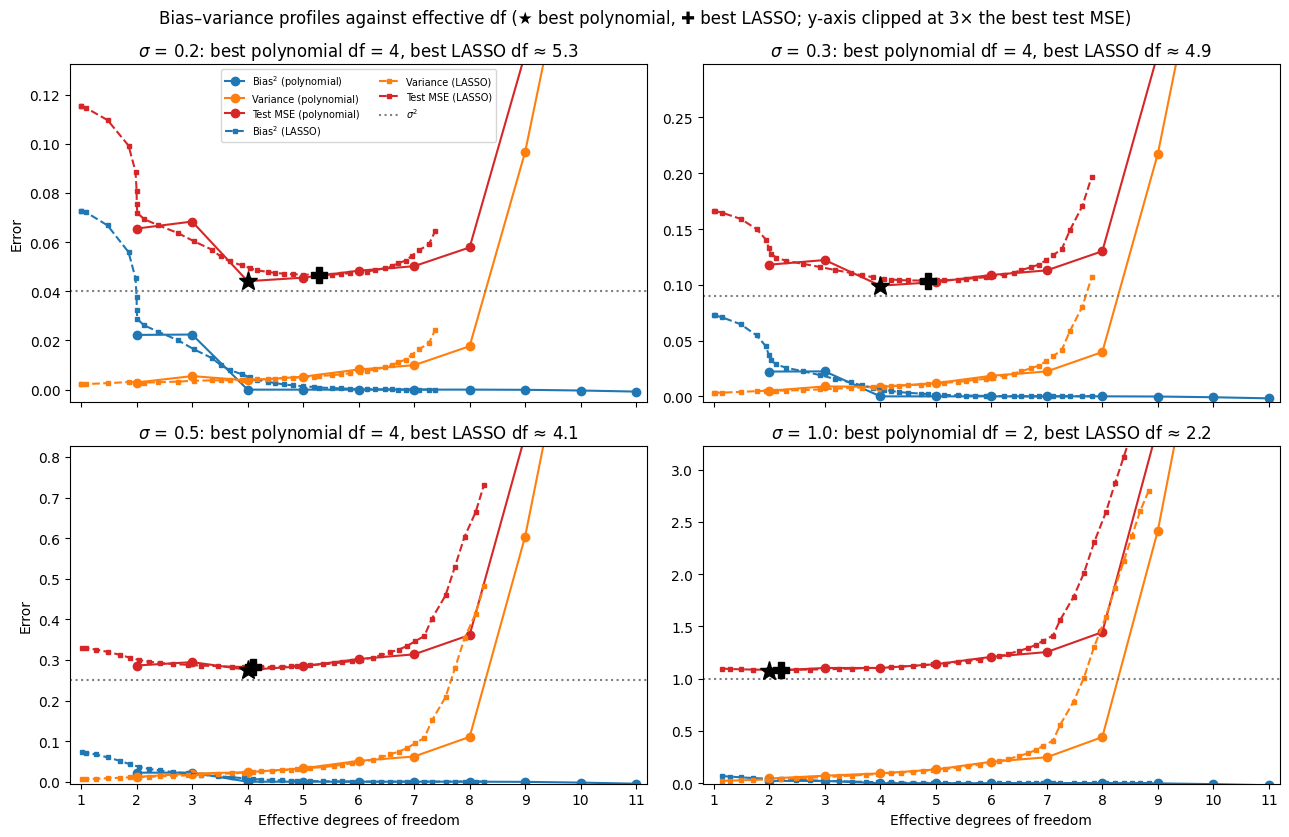

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True)
for ax, s in zip(axes.ravel(), SIGMAS):
    p, l = res[s], lasso_res[s]
    dfp = p.index.values + 1
    ax.plot(dfp, p['bias2'], 'o-', color='tab:blue', label=r'Bias$^2$ (polynomial)')
    ax.plot(dfp, p['variance'], 'o-', color='tab:orange', label='Variance (polynomial)')
    ax.plot(dfp, p['test_MSE'], 'o-', color='tab:red', label='Test MSE (polynomial)')
    ax.plot(l['df'], l['bias2'], 's--', ms=3, color='tab:blue', label=r'Bias$^2$ (LASSO)')
    ax.plot(l['df'], l['variance'], 's--', ms=3, color='tab:orange', label='Variance (LASSO)')
    ax.plot(l['df'], l['test_MSE'], 's--', ms=3, color='tab:red', label='Test MSE (LASSO)')
    ax.axhline(s**2, color='grey', ls=':', label=r'$\sigma^2$')
    bp, bl = p['test_MSE'].idxmin(), l['test_MSE'].idxmin()
    ax.plot(bp + 1, p.loc[bp, 'test_MSE'], 'k*', ms=14)
    ax.plot(l.loc[bl, 'df'], l.loc[bl, 'test_MSE'], 'kP', ms=11)
    ax.set_ylim(-0.005, 3 * min(p['test_MSE'].min(), l['test_MSE'].min()))
    ax.set_xlim(0.8, 11.2); ax.set_xticks(range(1, 12))
    ax.set_title(rf'$\sigma$ = {s}: best polynomial df = {bp + 1}, best LASSO df ≈ {l.loc[bl, "df"]:.1f}')
for ax in axes[1]: ax.set_xlabel('Effective degrees of freedom')
for ax in axes[:, 0]: ax.set_ylabel('Error')
axes[0, 0].legend(fontsize=7, ncol=2)
plt.suptitle('Bias–variance profiles against effective df (★ best polynomial, ✚ best LASSO; y-axis clipped at 3× the best test MSE)')
plt.tight_layout(); plt.show()

### 5.2 Checking the df estimate (H9)

The covariance definition of degrees of freedom is $\mathrm{df} = \sum_{i=1}^n \operatorname{Cov}(\hat y_i, y_i)/\sigma^2$, for a **fixed** set of training inputs. We fix the training inputs of run 1, draw 400 fresh noise vectors at σ = 0.3, refit the LASSO at every penalty each time, and estimate the covariances. As a check that the estimator works, the same calculation for degree-3 OLS should give df ≈ 4.

Degree-3 OLS: covariance df = 4.00 (exact value 4)


,df: nonzero count + 1,df: covariance definition
alpha,,
0.4000,1.00,1.04
0.2309,1.61,1.65
0.1333,2.00,2.06
0.0769,2.33,2.34
0.0444,3.31,3.27
0.0256,3.88,3.84
0.0148,4.34,4.33
0.0085,4.82,4.78
0.0049,5.28,5.27


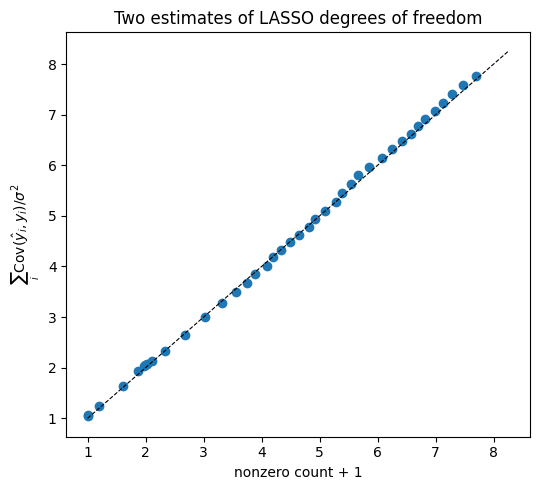

In [16]:
K, s = 400, BASE
xf = mc['X'][0]; n_ = len(xf)
F = xf[:, None] ** POWERS
Fs = StandardScaler().fit_transform(F)
Yrep = f(xf) + s * np.random.default_rng(SEED + 7).standard_normal((K, n_))
fitted = np.empty((K, len(LASSO_ALPHAS), n_)); nz = np.empty((K, len(LASSO_ALPHAS)))
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    for k in range(K):
        for j, a in enumerate(LASSO_ALPHAS):              # Lab 9: one Lasso fit per penalty
            m = Lasso(alpha=a, max_iter=300000, tol=1e-6).fit(Fs, Yrep[k])
            fitted[k, j] = m.predict(Fs)
            nz[k, j] = (np.abs(m.coef_) > 1e-10).sum()
Yc = Yrep - Yrep.mean(0)
df_cov = ((fitted - fitted.mean(0)) * Yc[:, None, :]).sum(axis=(0, 2)) / (K - 1) / s**2

feats3 = poly_pipe(3).fit(xf[:, None], Yrep[0])[:-1]     # degree-3 OLS (course pipeline), same fixed inputs
V3 = np.column_stack([np.ones(n_), feats3.transform(xf[:, None])])
fit3 = Yrep @ (V3 @ np.linalg.pinv(V3)).T                # OLS fitted values for every noise draw
df3 = ((fit3 - fit3.mean(0)) * Yc).sum() / (K - 1) / s**2
print(f'Degree-3 OLS: covariance df = {df3:.2f} (exact value 4)')

df_check = pd.DataFrame({'alpha': LASSO_ALPHAS, 'df: nonzero count + 1': nz.mean(0) + 1,
                         'df: covariance definition': df_cov}).set_index('alpha')
display(df_check.iloc[::3].round(2))
plt.figure(figsize=(5.5, 5))
plt.plot(df_check.iloc[:, 0], df_check.iloc[:, 1], 'o')
lim = [1, df_check.values.max() + 0.5]; plt.plot(lim, lim, 'k--', lw=0.8)
plt.xlabel('nonzero count + 1'); plt.ylabel(r'$\sum_i \mathrm{Cov}(\hat y_i, y_i) / \sigma^2$')
plt.title('Two estimates of LASSO degrees of freedom'); plt.tight_layout(); plt.show()

### 5.3 Best LASSO vs best polynomial at each noise level (H7, H8)

Because both families use the same training sets and the same test noise, the difference in test MSE is computed **run by run**, and its standard error comes from the 500 paired differences.

In [17]:
rows = []
for s in SIGMAS:
    p, l = res[s], lasso_res[s]
    bp, bl = int(p['test_MSE'].idxmin()), l['test_MSE'].idxmin()
    jl = int(np.argmin(l['test_MSE'].values))
    diff = lasso_raw[s]['mse_run'][:, jl] - raw[s]['mse_run'][:, bp - 1]
    se = diff.std(ddof=1) / np.sqrt(len(diff))
    rows.append(dict(sigma=s,
                     poly_best_degree=bp, poly_df=bp + 1, poly_test_MSE=p.loc[bp, 'test_MSE'],
                     lasso_best_alpha=bl, lasso_df=l.loc[bl, 'df'], lasso_test_MSE=l.loc[bl, 'test_MSE'],
                     lasso_bias2=l.loc[bl, 'bias2'], lasso_variance=l.loc[bl, 'variance'],
                     poly_bias2=p.loc[bp, 'bias2'], poly_variance=p.loc[bp, 'variance'],
                     MSE_difference_lasso_minus_poly=diff.mean(), paired_se=se, z=diff.mean() / se))
best_cmp = pd.DataFrame(rows).set_index('sigma')
best_cmp.round(4)

,poly_best_degree,poly_df,poly_test_MSE,lasso_best_alpha,lasso_df,lasso_test_MSE,lasso_bias2,lasso_variance,poly_bias2,poly_variance,MSE_difference_lasso_minus_poly,paired_se,z
sigma,,,,,,,,,,,,,
0.2,3,4,0.0441,0.0041,5.292,0.0467,0.0008,0.0056,-0.0000,0.0038,0.0026,0.0002,11.5698
0.3,3,4,0.0992,0.0085,4.854,0.1037,0.0020,0.0110,-0.0000,0.0085,0.0045,0.0004,10.9859
0.5,3,4,0.2756,0.0256,4.096,0.2823,0.0067,0.0236,-0.0000,0.0235,0.0068,0.0008,8.2076
1.0,1,2,1.0751,0.1601,2.216,1.0850,0.0371,0.0408,0.0221,0.0450,0.0099,0.0022,4.5921


### 5.4 Which powers does the LASSO keep?

The true function uses only $x$ and $x^3$. At each σ's best penalty we count how often the LASSO keeps exactly $\{x, x^3\}$, how often it keeps each of them, and the most common sets of powers.

In [18]:
rows, common = [], {}
for s in SIGMAS:
    jl = int(np.argmin(lasso_res[s]['test_MSE'].values))
    sup = lasso_support[s][:, jl, :]                       # (runs, powers)
    exact = sup[:, 0] & sup[:, 2] & (sup.sum(1) == 2)
    rows.append(dict(sigma=s, best_alpha=LASSO_ALPHAS[jl], mean_powers_kept=sup.sum(1).mean(),
                     share_keeps_x=sup[:, 0].mean(), share_keeps_x3=sup[:, 2].mean(),
                     share_exactly_x_and_x3=exact.mean()))
    sets = pd.Series(['{' + ', '.join(f'x^{p}' for p in POWERS[row]) + '}' for row in sup]).value_counts(normalize=True)
    common[s] = sets.head(3).round(3)
display(pd.DataFrame(rows).set_index('sigma').round(3))
for s in SIGMAS:
    print(f'sigma = {s}: most common sets of powers kept')
    print(common[s].to_string(), '\n')

,best_alpha,mean_powers_kept,share_keeps_x,share_keeps_x3,share_exactly_x_and_x3
sigma,,,,,
0.2,0.004,4.292,1.000,0.502,0.002
0.3,0.009,3.854,1.000,0.218,0.004
0.5,0.026,3.096,1.000,0.010,0.000
1.0,0.160,1.216,0.654,0.040,0.020


sigma = 0.2: most common sets of powers kept
{x^1, x^2, x^3, x^5, x^10}    0.110
{x^1, x^2, x^5, x^10}         0.074
{x^1, x^2, x^5, x^7, x^10}    0.050 

sigma = 0.3: most common sets of powers kept
{x^1, x^2, x^5, x^10}    0.118
{x^1, x^2, x^9, x^10}    0.054
{x^1, x^5, x^10}         0.052 

sigma = 0.5: most common sets of powers kept
{x^1, x^2, x^9}          0.106
{x^1, x^9, x^10}         0.078
{x^1, x^2, x^9, x^10}    0.078 

sigma = 1.0: most common sets of powers kept
{x^1}         0.372
{}            0.156
{x^1, x^2}    0.076 



LASSO shows a similar bias–variance trade-off to polynomial OLS, although it controls complexity by shrinking coefficients rather than selecting a polynomial degree. Starting with all ten polynomial powers, decreasing α at σ = 0.3 increases the average effective degrees of freedom from approximately 1 to 7.8. Squared bias falls from around 0.073 towards zero, while variance increases from approximately 0.003 to 0.107. Test MSE initially decreases, reaching a minimum of 0.1037, before increasing again. The LASSO curves also appear smoother because effective degrees of freedom are averaged over 500 simulations, even though the number of selected coefficients changes in discrete steps for each fit.

We also checked whether the number of nonzero coefficients, plus the intercept, provides a reasonable estimate of effective degrees of freedom. Using additional noise draws with fixed training inputs, the covariance-based estimate for degree-3 OLS was close to 4, as expected. For LASSO, both measures were generally similar, giving 4.82 and 4.78 at α ≈ 0.0085, for example. Although some differences remain due to Monte Carlo uncertainty, the results support using the nonzero coefficient count as our complexity measure.

Polynomial OLS achieves a lower minimum test MSE at every noise level. At σ = 0.2, the best polynomial model reaches 0.0441 compared with 0.0467 for LASSO, while at σ = 1 the values are 1.0751 and 1.0850. The paired differences exceed two standard errors in all four cases. However, LASSO's relative disadvantage falls from approximately 5.9% to 0.9% as noise increases, despite the absolute MSE difference becoming larger. Part of this decrease comes from the growing irreducible noise, although the relative gap also narrows after subtracting σ². Meanwhile, the optimal penalty increases from approximately 0.0041 to 0.1601, and average effective degrees of freedom fall from 5.29 to 2.22. LASSO therefore uses stronger regularisation as noise increases, but this is still not enough to outperform the best polynomial model in our experiment.

Another unexpected result concerns variable selection. Our true function only contains x and x³, yet LASSO selects exactly these two terms in at most 2% of simulations. At σ = 0.5, even x³ is selected in only 1% of runs. This seems counterintuitive given that the cubic term is part of the true function, but the polynomial powers are strongly correlated. LASSO can therefore select combinations of other powers that approximate the same relationship without necessarily losing much predictive accuracy. We can see here that predicting well and identifying the true variables are not necessarily the same thing.

There are also some limitations to consider. A few LASSO fits encounter convergence warnings at very small penalties. The convergence check in Part 5 (every fit at every penalty) shows these occur only at penalties below the ones that minimise test MSE, so they do not affect the comparison at the optimum, although they may affect the high-df end of the LASSO curves. More importantly, the comparisons use the best settings identified from the Monte Carlo test results. These are oracle comparisons rather than models selected independently from training data. For real data, we would instead use cross-validation, as demonstrated in Part 6, before evaluating the selected model on a separate test set.

## Part 6: Modelling-workflow demonstration (brief's five-step requirement)

The Monte Carlo study above is an oracle analysis: it reports *true* expected error and makes no selection decision. Whenever we actually **choose** a model from data (the family, the degree or λ), the brief's workflow applies. We demonstrate it on **one simulated dataset** (N = 100, σ = 0.3).

- **Split:** once, 80% train / 20% test (`random_state = 2026`).
- **CV metric:** mean squared prediction error, 10-fold CV, computed **inside the training set only** (shuffled `KFold`, `random_state = 2026`). The same folds are used for every candidate.
- **Candidates:** (a) polynomial OLS of degree 1–10 (course pipeline: `StandardScaler` → `PolynomialFeatures` → `LinearRegression`); (b) the LASSO on the standardised powers $x, \dots, x^{10}$ over the same 40 penalties as Part 5 (`PolynomialFeatures` → `StandardScaler` → `Lasso`, so standardisation is learned inside each training fold).
- **Selection rule:** the single candidate with the lowest CV MSE across both families. The one-SE choice within each family (lowest degree / largest λ within one SE of that family's minimum) is also reported.
- **Audit:** the test set is used exactly once, on the single chosen model.
- **Final model:** refit the chosen specification on all N = 100 observations.

In [19]:
# Step 1 — generate one dataset and split ONCE
rng = np.random.default_rng(SEED)
N = 100
x_all = rng.uniform(-1, 1, N)
y_all = f(x_all) + BASE * rng.standard_normal(N)
X_all = x_all.reshape(-1, 1)
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.2, random_state=SEED)
print('train / test sizes:', len(y_tr), len(y_te))

train / test sizes: 80 20


,cv_mse,cv_se
degree,,
1,0.1671,0.0255
2,0.1630,0.0250
3,0.1430,0.0245
4,0.1483,0.0258
5,0.1505,0.0257
6,0.1550,0.0254
7,0.1579,0.0262
8,0.1707,0.0301
9,0.2078,0.0479


Polynomial: CV-minimum degree 3 (CV MSE 0.1430); one-SE degree 1
LASSO:      CV-minimum alpha 0.0041 (CV MSE 0.1472); one-SE alpha 0.0641


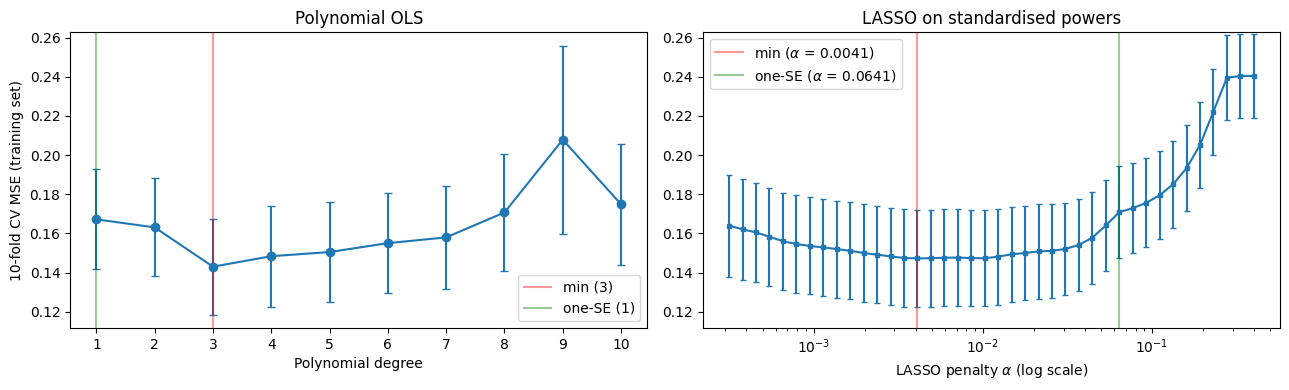

In [20]:
# Steps 2–3 — all comparisons use CV within the training set (metric: 10-fold CV MSE, same folds throughout)
kf = KFold(n_splits=10, shuffle=True, random_state=SEED)

def cv_scores(model):
    sc = -cross_val_score(model, X_tr, y_tr, cv=kf, scoring='neg_mean_squared_error')
    return sc.mean(), sc.std(ddof=1) / np.sqrt(len(sc))

# (a) polynomial OLS
pipe = Pipeline([('scale', StandardScaler()),
                 ('poly',  PolynomialFeatures(include_bias=False)),
                 ('ols',   LinearRegression())])
cv_mean, cv_se = np.array([cv_scores(pipe.set_params(poly__degree=int(d))) for d in DEGREES]).T
d_min = int(DEGREES[cv_mean.argmin()])
d_1se = int(DEGREES[np.argmax(cv_mean <= cv_mean.min() + cv_se[cv_mean.argmin()])])
cv_table = pd.DataFrame({'degree': DEGREES, 'cv_mse': cv_mean, 'cv_se': cv_se}).set_index('degree')

# (b) LASSO on standardised powers (standardisation learned inside each fold)
lasso_pipe = Pipeline([('poly',  PolynomialFeatures(degree=10, include_bias=False)),
                       ('scale', StandardScaler()),
                       ('lasso', Lasso(max_iter=300000, tol=1e-6))])
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    lcv_mean, lcv_se = np.array([cv_scores(lasso_pipe.set_params(lasso__alpha=a)) for a in LASSO_ALPHAS]).T
a_min = LASSO_ALPHAS[lcv_mean.argmin()]
a_1se = LASSO_ALPHAS[np.argmax(lcv_mean <= lcv_mean.min() + lcv_se[lcv_mean.argmin()])]  # grid runs largest -> smallest
lasso_cv_table = pd.DataFrame({'alpha': LASSO_ALPHAS, 'cv_mse': lcv_mean, 'cv_se': lcv_se}).set_index('alpha')

display(cv_table)
print(f'Polynomial: CV-minimum degree {d_min} (CV MSE {cv_mean.min():.4f}); one-SE degree {d_1se}')
print(f'LASSO:      CV-minimum alpha {a_min:.4f} (CV MSE {lcv_mean.min():.4f}); one-SE alpha {a_1se:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].errorbar(DEGREES, cv_mean, yerr=cv_se, fmt='o-', capsize=3)
axes[0].axvline(d_min, color='r', alpha=.4, label=f'min ({d_min})'); axes[0].axvline(d_1se, color='g', alpha=.4, label=f'one-SE ({d_1se})')
axes[0].set_xlabel('Polynomial degree'); axes[0].set_ylabel('10-fold CV MSE (training set)'); axes[0].set_xticks(DEGREES); axes[0].legend()
axes[0].set_title('Polynomial OLS')
axes[1].errorbar(LASSO_ALPHAS, lcv_mean, yerr=lcv_se, fmt='s-', ms=3, capsize=2)
axes[1].axvline(a_min, color='r', alpha=.4, label=rf'min ($\alpha$ = {a_min:.4f})'); axes[1].axvline(a_1se, color='g', alpha=.4, label=rf'one-SE ($\alpha$ = {a_1se:.4f})')
axes[1].set_xscale('log'); axes[1].set_xlabel(r'LASSO penalty $\alpha$ (log scale)'); axes[1].legend()
axes[1].set_ylim(axes[0].get_ylim()); axes[1].set_title('LASSO on standardised powers')
plt.tight_layout(); plt.show()

As declared in the set-up above, we select the candidate with the lowest 10-fold CV MSE across both families (polynomial degrees 1-10 and the LASSO penalties). Hence, we carry forward the polynomial OLS of degree 3 [CHOSEN = ('poly', 3)]. Its 10-fold CV MSE is (0.1430, SE ≈ 0.025). The best LASSO numeric is (α = 0.0041, CV MSE 0.1472). The difference in CV MSE (0.004) is much smaller than 1 SE (about 0.025), so the two families are statistically tied and we follow the pre-declared rule.

We also do not select the 1 SE choices. The CV MSE numeric from degree 1 only just qualifies (0.1671) and our selection experiment shows that the rule often picks a degree below 3, (49% of datasets at σ = 0.3). Degree 3 also matches the oracle optimum from the Monte Carlo study at (n = 80, σ = 0.3).

Note that the test is ran once, and only for this model.

In [21]:
# Step 4 — the test set is touched exactly once, for the single chosen model
CHOSEN = ('poly', d_min) if cv_mean.min() <= lcv_mean.min() else ('lasso', a_min)

def build(choice):
    family, value = choice
    if family == 'poly':
        return Pipeline([('scale', StandardScaler()),
                         ('poly',  PolynomialFeatures(degree=int(value), include_bias=False)),
                         ('ols',   LinearRegression())])
    return Pipeline([('poly',  PolynomialFeatures(degree=10, include_bias=False)),
                     ('scale', StandardScaler()),
                     ('lasso', Lasso(alpha=value, max_iter=300000, tol=1e-6))])

final = build(CHOSEN).fit(X_tr, y_tr)
test_mse = np.mean((y_te - final.predict(X_te))**2)
chosen_cv = cv_table.loc[CHOSEN[1], 'cv_mse'] if CHOSEN[0] == 'poly' else lasso_cv_table.loc[CHOSEN[1], 'cv_mse']
print(f'Chosen model {CHOSEN}:  CV MSE (train) = {chosen_cv:.4f}   test MSE (audit, once) = {test_mse:.4f}   sigma^2 = {BASE**2:.4f}')

Chosen model ('poly', 3):  CV MSE (train) = 0.1430   test MSE (audit, once) = 0.1036   sigma^2 = 0.0900


In [22]:
# Step 5 — refit the exact chosen specification on ALL data (train + test)
final = build(CHOSEN).fit(X_all, y_all)
if CHOSEN[0] == 'poly':
    est = final.named_steps['ols']
    names = ['intercept'] + [f'x^{k}' for k in range(1, int(CHOSEN[1]) + 1)]
    print('Final model coefficients (polynomial terms of standardised x):')
else:
    est = final.named_steps['lasso']
    names = ['intercept'] + [f'x^{k}' for k in POWERS]
    print('Final model coefficients (standardised powers of x; zeros were dropped by the LASSO):')
print(pd.Series(np.r_[est.intercept_, est.coef_], index=names).round(4).to_string())

# Compare with the oracle optimum at the matching training size (n = 80)
mc80 = run_mc(n=80, R=300, seed=SEED + 1, sigmas=[BASE])
oracle80 = decompose(mc80, BASE, n_boot=0)[0]['test_MSE'].idxmin()
print(f'\nOracle optimum for polynomial OLS (Monte Carlo, n = 80, sigma = {BASE}): degree {oracle80};  '
      f'CV chose degree {d_min} (min) / {d_1se} (one-SE) within the polynomial family.')

Final model coefficients (polynomial terms of standardised x):
intercept   -0.0178
x^1         -0.6355
x^2          0.0436
x^3          0.1845

Oracle optimum for polynomial OLS (Monte Carlo, n = 80, sigma = 0.3): degree 3;  CV chose degree 3 (min) / 1 (one-SE) within the polynomial family.


### 6.1 How reliable is CV-based degree selection?

For each σ we generate 200 independent datasets of n = 50, and choose the degree by 5-fold CV on each dataset using the minimum rule and one-SE rule.

In [23]:
def cv_select(x, y, k=5, seed=0):
    kf_ = KFold(k, shuffle=True, random_state=seed)
    err = np.column_stack([-cross_val_score(poly_pipe(d), x[:, None], y, cv=kf_, scoring='neg_mean_squared_error')
                           for d in DEGREES])                # (folds, degrees), course pipeline
    m = err.mean(0); se = err.std(0, ddof=1) / np.sqrt(k)
    j_min = m.argmin()
    return DEGREES[j_min], DEGREES[np.argmax(m <= m[j_min] + se[j_min])]

rows = []
for s in SIGMAS:
    picks = np.array([cv_select(mc['X'][r], f(mc['X'][r]) + s * mc['Z'][r], seed=r) for r in range(200)])
    rows.append(dict(sigma=s,
                     oracle_degree=res[s]['test_MSE'].idxmin(),
                     min_rule_mean=picks[:, 0].mean(), min_rule_share_of_3=(picks[:, 0] == 3).mean(),
                     min_rule_share_below_3=(picks[:, 0] < 3).mean(), min_rule_share_above_3=(picks[:, 0] > 3).mean(),
                     one_se_mean=picks[:, 1].mean(), one_se_share_of_3=(picks[:, 1] == 3).mean(),
                     one_se_share_below_3=(picks[:, 1] < 3).mean(), one_se_share_above_3=(picks[:, 1] > 3).mean()))
pd.DataFrame(rows).set_index('sigma')

,oracle_degree,min_rule_mean,min_rule_share_of_3,min_rule_share_below_3,min_rule_share_above_3,one_se_mean,one_se_share_of_3,one_se_share_below_3,one_se_share_above_3
sigma,,,,,,,,,
0.2,3,3.765,0.650,0.000,0.350,2.84,0.820,0.130,0.050
0.3,3,3.605,0.580,0.080,0.340,2.14,0.465,0.490,0.045
0.5,3,2.890,0.330,0.385,0.285,1.41,0.135,0.835,0.030
1.0,1,2.330,0.095,0.675,0.230,1.11,0.020,0.970,0.010


The CV carried forward the polynomial OLS of degree 3 (10-fold CV MSE = 0.1430). The other family was pretty close as the best LASSO (α = 0.0041) scored 0.1472, a minute gap of 0.004 against a CV SE of about 0.025; the two are statistically tied and our declared rule stands. Within the polynomial family, CV chose the oracle degree [Monte Carlo optimum at n = 80, σ = 0.3 is also 3]. On the contrary, the 1 SE rule picked degree 1.

The MSE from the single test audit is 0.1036, below the CV estimate of 0.1430 and about 0.014 above the noise floor σ² = 0.09. It's a noisy draw as we used only 20 test points, the fact that it is lower than the CV is hence of lower importance.

Across the 200 independent datasets in our experiment (n = 50, 5-fold CV), the min. rule selects degree 3 in 65%, 58%, 33% and 9.5% of datasets at σ = 0.2, 0.3, 0.5 and 1.0 respectively. Furthermore, the 1 SE rule picks it in 82%, 46.5%, 13.5% and 2% respectively. Both shares fall as noise rises, but, at σ = 1 the oracle degree is 1, so a low share of '3' there is not a failure.

The two rules are in contrast as:
- The minimum rule over-picks (>3 in 23–35% of datasets), accepting variance.
- The one-SE rule under-picks (<3 in 49% of datasets at σ = 0.3, 97% at σ = 1.0), and bias is traded for simplicity.

This trade costs accuracy at low noise (σ ≤ 0.5), where the cubic is worth estimating, and helps when noise is high, where its mean pick of 1.11 is close to the oracle degree of 1.